#### Importing Required Libraries


In [4]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

#### Loading the Dataset


In [5]:
from pathlib import Path

DATA_DIR = Path("../data/raw")

features = pd.read_csv(
    DATA_DIR / "NUSW-NB15_features.csv",
    encoding="cp1252"
)

column_names = features["Name"].tolist()

files = [
    "UNSW-NB15_1.csv",
    "UNSW-NB15_2.csv",
    "UNSW-NB15_3.csv",
    "UNSW-NB15_4.csv"
]

dataframes = []

for file in files:
    temp_df = pd.read_csv(
        DATA_DIR / file,
        header=None,
        low_memory=False
    )

    temp_df.columns = column_names
    dataframes.append(temp_df)

df = pd.concat(dataframes, ignore_index=True)

df = df.rename(columns={"ct_src_ ltm": "ct_src_ltm"})
df["attack_cat"] = df["attack_cat"].str.strip()

#### Checking Dataset Dimensions

In [6]:
for i, data in enumerate(dataframes, start=1):
    print(f"Dataset {i}: {data.shape}")

print("\nCombined Dataset:", df.shape)
print("Total Records:", f"{df.shape[0]:,}")
print("Total Features:", df.shape[1])

Dataset 1: (700001, 49)
Dataset 2: (700001, 49)
Dataset 3: (700001, 49)
Dataset 4: (440044, 49)

Combined Dataset: (2540047, 49)
Total Records: 2,540,047
Total Features: 49


#### Inspecting the Dataset

In [7]:
df.head()

,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,Label
0,59.166.0.0,1390,149.171.126.6,53,udp,CON,0.001055,132,164,31,...,0,3,7,1,3,1,1,1,NaN,0
1,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.036133,528,304,31,...,0,2,4,2,3,1,1,2,NaN,0
2,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.001119,146,178,31,...,0,12,8,1,2,2,1,1,NaN,0
3,59.166.0.5,3593,149.171.126.5,53,udp,CON,0.001209,132,164,31,...,0,6,9,1,1,1,1,1,NaN,0
4,59.166.0.3,49664,149.171.126.0,53,udp,CON,0.001169,146,178,31,...,0,7,9,1,1,1,1,1,NaN,0


#### Inspecting Column Data Types

In [8]:
df.dtypes

srcip                   str
sport                object
dstip                   str
dsport                  str
proto                   str
state                   str
dur                 float64
sbytes                int64
dbytes                int64
sttl                  int64
dttl                  int64
sloss                 int64
dloss                 int64
service                 str
Sload               float64
Dload               float64
Spkts                 int64
Dpkts                 int64
swin                  int64
dwin                  int64
stcpb                 int64
dtcpb                 int64
smeansz               int64
dmeansz               int64
trans_depth           int64
res_bdy_len           int64
Sjit                float64
Djit                float64
Stime                 int64
Ltime                 int64
Sintpkt             float64
Dintpkt             float64
tcprtt              float64
synack              float64
ackdat              float64
is_sm_ips_ports     

#### Counting Columns by Data Type

In [9]:
df.dtypes.value_counts()

int64      28
float64    12
str         7
object      2
Name: count, dtype: int64

#### Identifying Missing Values

In [10]:
df.isnull().sum()

srcip                     0
sport                     0
dstip                     0
dsport                    0
proto                     0
state                     0
dur                       0
sbytes                    0
dbytes                    0
sttl                      0
dttl                      0
sloss                     0
dloss                     0
service                   0
Sload                     0
Dload                     0
Spkts                     0
Dpkts                     0
swin                      0
dwin                      0
stcpb                     0
dtcpb                     0
smeansz                   0
dmeansz                   0
trans_depth               0
res_bdy_len               0
Sjit                      0
Djit                      0
Stime                     0
Ltime                     0
Sintpkt                   0
Dintpkt                   0
tcprtt                    0
synack                    0
ackdat                    0
is_sm_ips_ports     

#### Checking Missing-Value Percentages

In [11]:
missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": (missing / len(df)) * 100
})

missing_summary[missing_summary["Missing Values"] > 0]

,Missing Values,Missing Percentage
ct_flw_http_mthd,1348145,53.075593
is_ftp_login,1429879,56.293407
attack_cat,2218764,87.351297


#### Comparing Missing Values Against the Binary Target

In [12]:
df.groupby("Label")[["ct_flw_http_mthd", "is_ftp_login", "attack_cat"]].apply(
    lambda group: group.isnull().sum()
)

,ct_flw_http_mthd,is_ftp_login,attack_cat
Label,,,
0,1065206,1132696,2218764
1,282939,297183,0


#### Verifying the Relationship Between Label and Attack Category

In [13]:
pd.crosstab(
    df["Label"],
    df["attack_cat"].fillna("Normal"),
    dropna=False
)

attack_cat,Analysis,Backdoor,Backdoors,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Shellcode,Worms
Label,,,,,,,,,,,
0,0,0,0,0,0,0,0,2218764,0,0,0
1,2677,1795,534,16353,44525,24246,215481,0,13987,1511,174


#### Inspecting Unique Attack Categories

In [14]:
for category in df["attack_cat"].dropna().unique():
    print(repr(category))

'Exploits'
'Reconnaissance'
'DoS'
'Generic'
'Shellcode'
'Fuzzers'
'Worms'
'Backdoors'
'Analysis'
'Backdoor'


#### Checking Binary Target Distribution

In [15]:
df["Label"].value_counts()

Label
0    2218764
1     321283
Name: count, dtype: int64

#### Checking Binary Target Proportions

In [16]:
df["Label"].value_counts(normalize=True) * 100

Label
0    87.351297
1    12.648703
Name: proportion, dtype: float64

#### Visualizing Binary Target Distribution

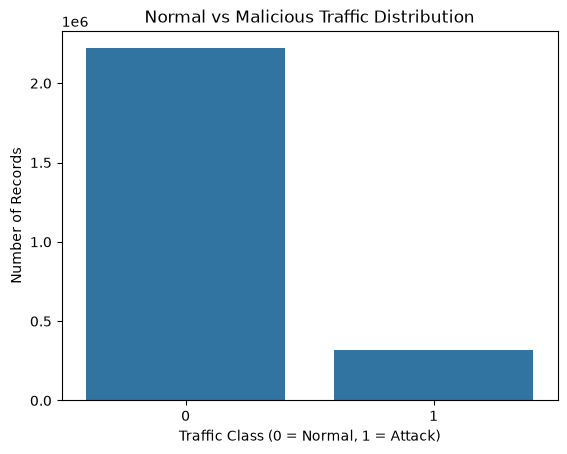

In [17]:
sns.countplot(data=df, x="Label")

plt.title("Normal vs Malicious Traffic Distribution")
plt.xlabel("Traffic Class (0 = Normal, 1 = Attack)")
plt.ylabel("Number of Records")
plt.show()

#### Multiclass Target Distribution

In [18]:
df["attack_cat"].value_counts()

attack_cat
Generic           215481
Exploits           44525
Fuzzers            24246
DoS                16353
Reconnaissance     13987
Analysis            2677
Backdoor            1795
Shellcode           1511
Backdoors            534
Worms                174
Name: count, dtype: int64

#### Checking Multiclass Target Proportions

In [19]:
df["attack_cat"].value_counts(normalize=True) * 100

attack_cat
Generic           67.068908
Exploits          13.858499
Fuzzers            7.546618
DoS                5.089905
Reconnaissance     4.353483
Analysis           0.833222
Backdoor           0.558697
Shellcode          0.470302
Backdoors          0.166209
Worms              0.054158
Name: proportion, dtype: float64

#### Visualizing Attack Category Distribution

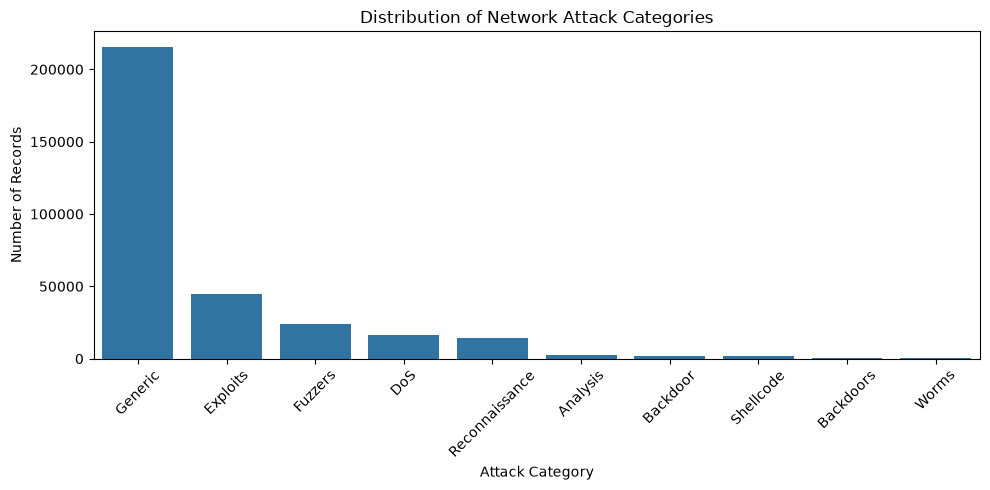

In [20]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df[df["attack_cat"].notna()],
    x="attack_cat",
    order=df["attack_cat"].value_counts().index
)

plt.title("Distribution of Network Attack Categories")
plt.xlabel("Attack Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Examining Numerical Feature Distributions

In [21]:
df.describe()

,dur,sbytes,dbytes,sttl,dttl,sloss,dloss,Sload,Dload,Spkts,...,ct_flw_http_mthd,is_ftp_login,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,Label
count,2.540047e+06,2.540047e+06,2.540047e+06,2.540047e+06,2.540047e+06,2.540047e+06,2.540047e+06,2.540047e+06,2.540047e+06,2.540047e+06,...,1.191902e+06,1.110168e+06,2.540047e+06,2.540047e+06,2.540047e+06,2.540047e+06,2.540047e+06,2.540047e+06,2.540047e+06,2.540047e+06
mean,6.587916e-01,4.339600e+03,3.642759e+04,6.278197e+01,3.076681e+01,5.163921e+00,1.632944e+01,3.695645e+07,2.450861e+06,3.328884e+01,...,2.345856e-01,3.969940e-02,9.206988e+00,8.988958e+00,6.439103e+00,6.900986e+00,4.642139e+00,3.592729e+00,6.845886e+00,1.264870e-01
std,1.392493e+01,5.640599e+04,1.610960e+05,7.462277e+01,4.285089e+01,2.251707e+01,5.659474e+01,1.186043e+08,4.224863e+06,7.628388e+01,...,7.940924e-01,1.996589e-01,1.083676e+01,1.082249e+01,8.162034e+00,8.205062e+00,8.477579e+00,6.174445e+00,1.125828e+01,3.323975e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00
25%,1.037000e-03,2.000000e+02,1.780000e+02,3.100000e+01,2.900000e+01,0.000000e+00,0.000000e+00,1.353963e+05,1.191594e+04,2.000000e+00,...,0.000000e+00,0.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00
50%,1.586100e-02,1.470000e+03,1.820000e+03,3.100000e+01,2.900000e+01,3.000000e+00,4.000000e+00,5.893038e+05,5.893179e+05,1.200000e+01,...,0.000000e+00,0.000000e+00,5.000000e+00,5.000000e+00,3.000000e+00,4.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,0.000000e+00
75%,2.145545e-01,3.182000e+03,1.489400e+04,3.100000e+01,2.900000e+01,7.000000e+00,1.400000e+01,2.039923e+06,2.925974e+06,4.400000e+01,...,0.000000e+00,0.000000e+00,1.000000e+01,1.000000e+01,6.000000e+00,7.000000e+00,2.000000e+00,1.000000e+00,5.000000e+00,0.000000e+00
max,8.786638e+03,1.435577e+07,1.465753e+07,2.550000e+02,2.540000e+02,5.319000e+03,5.507000e+03,5.988000e+09,1.287619e+08,1.064600e+04,...,3.600000e+01,4.000000e+00,6.700000e+01,6.700000e+01,6.700000e+01,6.700000e+01,6.700000e+01,6.000000e+01,6.700000e+01,1.000000e+00


#### Visualizing Numerical Feature Distributions

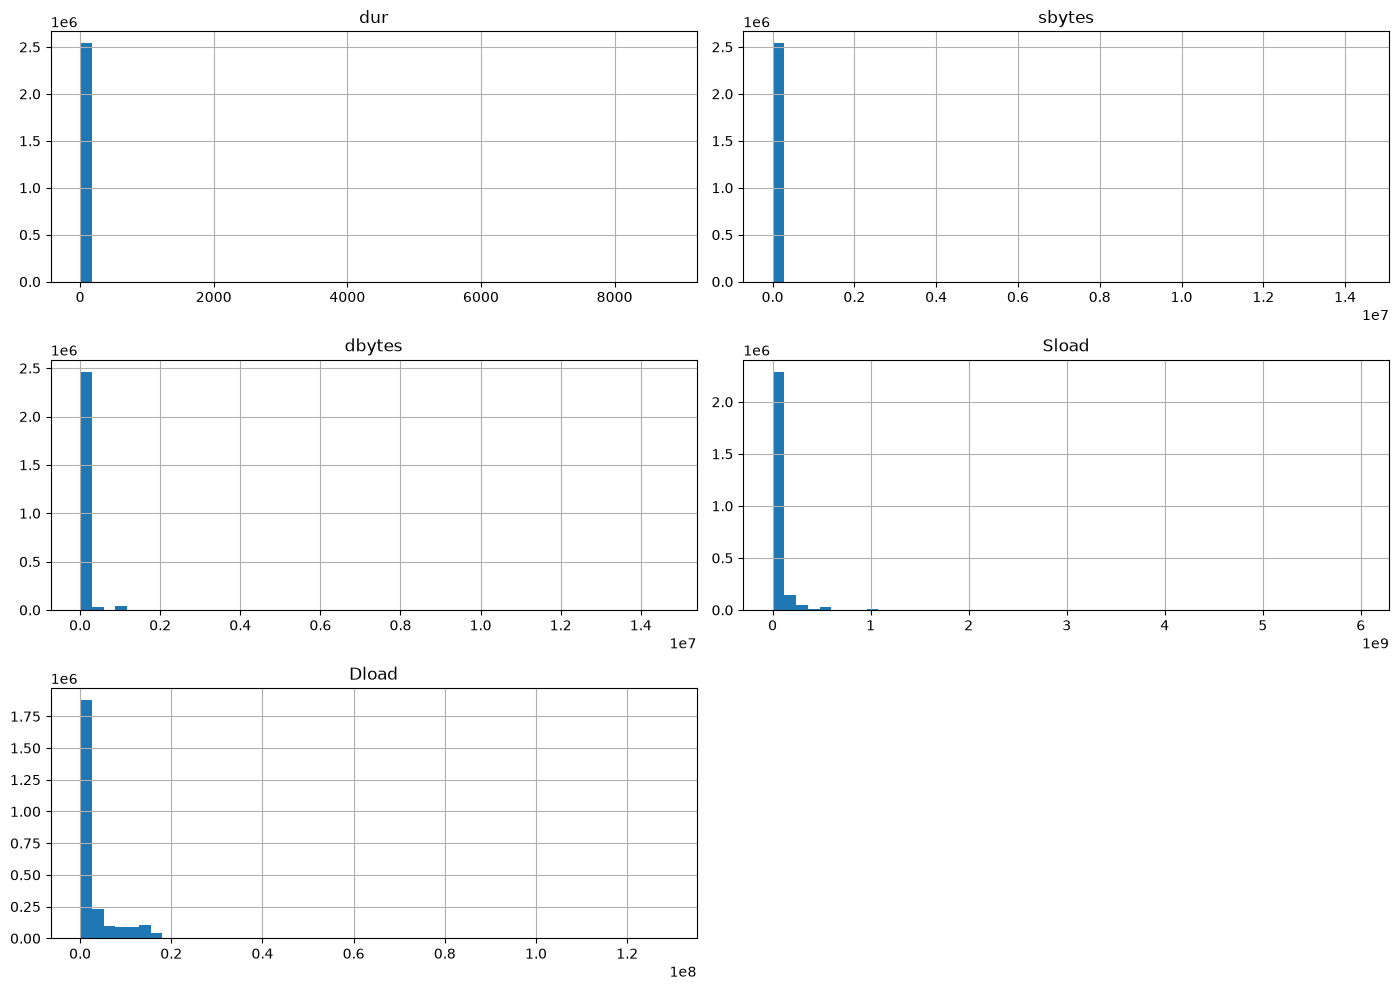

In [22]:
numerical_features = [
    "dur",
    "sbytes",
    "dbytes",
    "Sload",
    "Dload"
]

df[numerical_features].hist(
    bins=50,
    figsize=(14, 10)
)

plt.tight_layout()
plt.show()

#### Quantifying Skewness

In [23]:
df[numerical_features].skew().sort_values(ascending=False)

dur       590.036391
sbytes    142.981858
dbytes      9.089084
Sload       7.525025
Dload       1.955561
dtype: float64

#### Calculating IQR-Based Outlier Boundaries

In [24]:
Q1 = df[numerical_features].quantile(0.25)
Q3 = df[numerical_features].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = (
    (df[numerical_features] < lower_bound) |
    (df[numerical_features] > upper_bound)
).sum()

print(outlier_counts.sort_values(ascending=False))

Sload     563157
dur       451297
Dload     344566
dbytes    301908
sbytes    287942
dtype: int64


#### Visualizing Outliers Using Boxplots

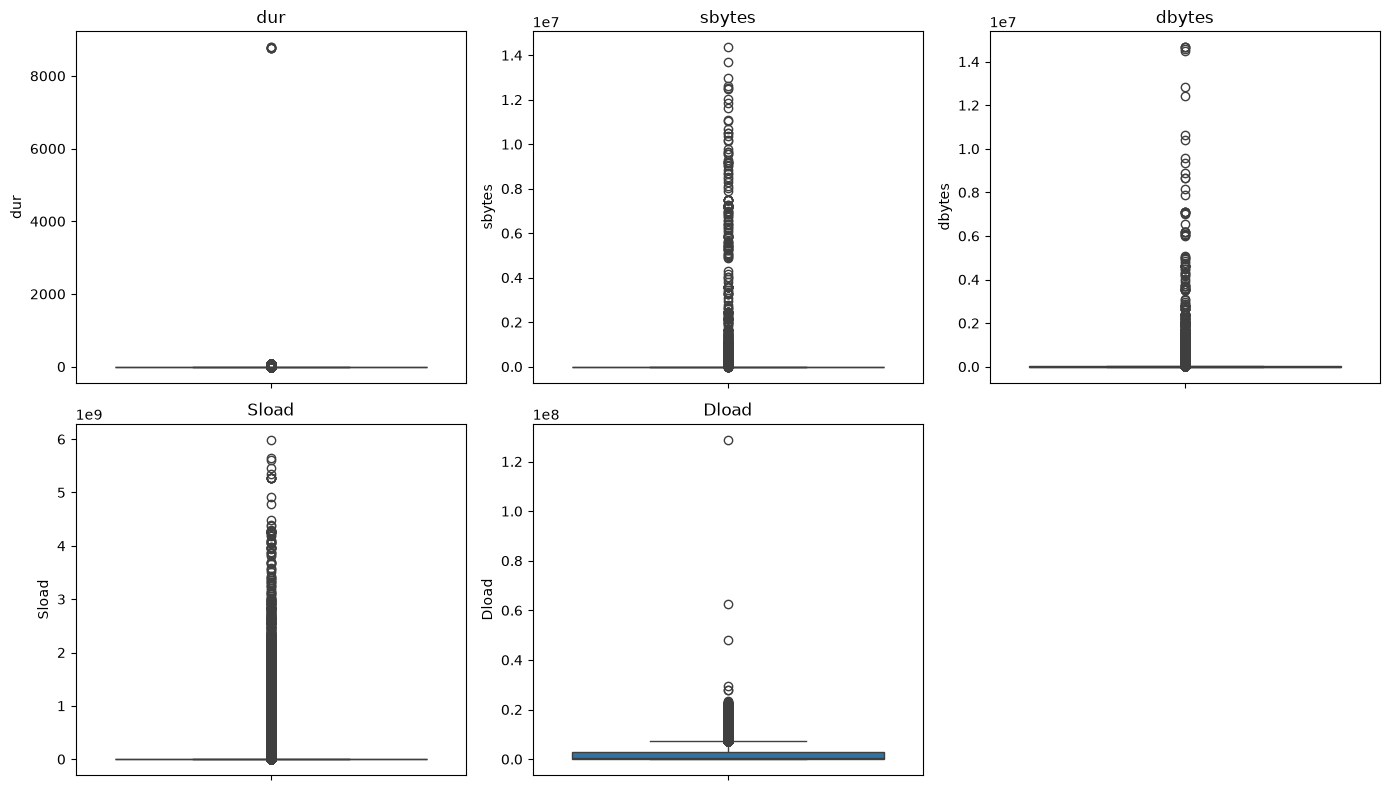

In [25]:
plt.figure(figsize=(14, 8))

for i, feature in enumerate(numerical_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[feature])
    plt.title(feature)

plt.tight_layout()
plt.show()

#### Examining Categorical Features

In [26]:
categorical_features = [
    col for col in df.columns
    if df[col].dtype in ["object", "str"]
]

print("Categorical features:", categorical_features)

for feature in categorical_features:
    print(f"\n{feature}:")
    print(df[feature].value_counts().head(10))

Categorical features: ['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'service', 'ct_ftp_cmd', 'attack_cat']

srcip:
srcip
59.166.0.4    197959
59.166.0.1    197680
59.166.0.5    197626
59.166.0.2    197550
59.166.0.0    197528
59.166.0.3    195953
59.166.0.9    190187
59.166.0.6    189419
59.166.0.8    189341
59.166.0.7    189059
Name: count, dtype: int64

sport:
sport
1043     214363
47439    196337
0         44376
0          9668
47439      6932
1043       5959
138        3480
5060        448
137         362
2048        357
Name: count, dtype: int64

dstip:
dstip
149.171.126.3    197771
149.171.126.2    197648
149.171.126.4    197639
149.171.126.1    197535
149.171.126.5    197000
149.171.126.0    196770
149.171.126.9    190483
149.171.126.7    190268
149.171.126.6    189709
149.171.126.8    187479
Name: count, dtype: int64

dsport:
dsport
53      798968
80      226698
6881    125156
5190    120599
111      93296
25       88748
0        54091
143      51065
22       50827
21

#### Examining Categorical Feature Cardinality

In [27]:
for feature in categorical_features:
    print(f"{feature}: {df[feature].nunique()} unique values")

srcip: 43 unique values
sport: 129124 unique values
dstip: 47 unique values
dsport: 64630 unique values
proto: 135 unique values
state: 16 unique values
service: 13 unique values
ct_ftp_cmd: 13 unique values
attack_cat: 10 unique values


#### Inspecting Duplicate Records

In [28]:
print("Duplicate records:", df.duplicated().sum())

print(
    "Duplicate percentage:",
    (df.duplicated().sum() / len(df)) * 100
)

Duplicate records: 480632
Duplicate percentage: 18.922169550405957


#### Checking Duplicate Records Against Target Labels

In [ ]:
duplicate_rows = df[df.duplicated(keep=False)]

pd.crosstab(
    duplicate_rows["Label"],
    duplicate_rows["attack_cat"].fillna("Normal")
)

#### Checking Conflicting Duplicate Labels

In [29]:
feature_columns = df.columns.drop(["Label", "attack_cat"])

feature_hash = pd.util.hash_pandas_object(
    df[feature_columns],
    index=False
)

duplicate_check = pd.DataFrame({
    "feature_hash": feature_hash,
    "Label": df["Label"],
    "attack_cat": df["attack_cat"]
})

grouped = duplicate_check.groupby("feature_hash", sort=False).agg(
    label_count=("Label", "nunique"),
    attack_count=("attack_cat", "nunique")
)

print(
    "Identical feature groups with conflicting binary labels:",
    (grouped["label_count"] > 1).sum()
)

print(
    "Identical feature groups with multiple attack categories:",
    (grouped["attack_count"] > 1).sum()
)

Identical feature groups with conflicting binary labels: 0
Identical feature groups with multiple attack categories: 2251


#### Summarizing Conflicting Attack Categories

In [30]:
conflicting_groups = grouped[grouped["attack_count"] > 1]

print("Conflicting feature groups:", len(conflicting_groups))

print(
    "Total distinct attack categories across conflicting groups:",
    conflicting_groups["attack_count"].sum()
)

Conflicting feature groups: 2251
Total distinct attack categories across conflicting groups: 13049


#### EDA Summary

In [31]:
print("Dataset Dimensions:", df.shape)

print("\nBinary Target Distribution:")
print(df["Label"].value_counts())

print("\nAttack Category Distribution:")
print(df["attack_cat"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nExact Duplicate Records:", df.duplicated().sum())

print("\nConflicting Binary Label Groups:", (grouped["label_count"] > 1).sum())

print("Conflicting Attack Category Groups:", (grouped["attack_count"] > 1).sum())

Dataset Dimensions: (2540047, 49)

Binary Target Distribution:
Label
0    2218764
1     321283
Name: count, dtype: int64

Attack Category Distribution:
attack_cat
Generic           215481
Exploits           44525
Fuzzers            24246
DoS                16353
Reconnaissance     13987
Analysis            2677
Backdoor            1795
Shellcode           1511
Backdoors            534
Worms                174
Name: count, dtype: int64

Missing Values:
ct_flw_http_mthd    1348145
is_ftp_login        1429879
attack_cat          2218764
dtype: int64

Exact Duplicate Records: 480632

Conflicting Binary Label Groups: 0
Conflicting Attack Category Groups: 2251


#### Understanding Feature Types and Roles

In [32]:
target_columns = ["Label", "attack_cat"]

feature_columns = [
    col for col in df.columns
    if col not in target_columns
]

print("Total Features:", len(feature_columns))
print("Target Columns:", target_columns)

print("\nFeature Columns:")
print(feature_columns)

Total Features: 47
Target Columns: ['Label', 'attack_cat']

Feature Columns:
['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'service', 'Sload', 'Dload', 'Spkts', 'Dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'Sjit', 'Djit', 'Stime', 'Ltime', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm']


#### Separating Numerical and Categorical Features

In [33]:
numerical_features = df[feature_columns].select_dtypes(
    include="number"
).columns.tolist()

categorical_features = df[feature_columns].select_dtypes(
    include=["object", "str", "string"]
).columns.tolist()

print("Numerical Features:", len(numerical_features))
print(numerical_features)

print("\nCategorical Features:", len(categorical_features))
print(categorical_features)

Numerical Features: 39
['dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'Sload', 'Dload', 'Spkts', 'Dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'Sjit', 'Djit', 'Stime', 'Ltime', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm']

Categorical Features: 8
['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'service', 'ct_ftp_cmd']


#### Identifying Missing Values in Features

In [34]:
missing = df[feature_columns].isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": (missing / len(df)) * 100
})

missing_summary[missing_summary["Missing Values"] > 0]

,Missing Values,Missing Percentage
ct_flw_http_mthd,1348145,53.075593
is_ftp_login,1429879,56.293407


#### Analyzing Missing Values by Network Service

In [35]:
missing_by_service = df.groupby("service", dropna=False)[
    ["ct_flw_http_mthd", "is_ftp_login"]
].apply(lambda group: group.isnull().sum())

missing_by_service

,ct_flw_http_mthd,is_ftp_login
service,,
-,595228,596013
dhcp,165,165
dns,588156,588156
ftp,24229,1267
ftp-data,64115,64115
http,8044,111955
irc,28,28
pop3,1327,1327
radius,33,33


#### Examining Non-Missing Values

In [36]:
print("ct_flw_http_mthd:")
print(df["ct_flw_http_mthd"].value_counts(dropna=False).sort_index())

print("\nis_ftp_login:")
print(df["is_ftp_login"].value_counts(dropna=False).sort_index())

ct_flw_http_mthd:
ct_flw_http_mthd
0.0      986791
1.0      188008
2.0         588
3.0         738
4.0        6564
5.0         430
6.0        7902
8.0          56
9.0         270
10.0         30
12.0        132
14.0        224
16.0         48
25.0         25
30.0         60
36.0         36
NaN     1348145
Name: count, dtype: int64

is_ftp_login:
is_ftp_login
0.0    1066593
1.0      43389
2.0         30
4.0        156
NaN    1429879
Name: count, dtype: int64


#### Checking Missing Values by Target Class

In [37]:
df.groupby("Label")[["ct_flw_http_mthd", "is_ftp_login"]].apply(
    lambda group: group.isnull().sum()
)

,ct_flw_http_mthd,is_ftp_login
Label,,
0,1065206,1132696
1,282939,297183


#### Checking Missing-Value Percentages by Target Class

In [38]:
missing_by_label = df.groupby("Label")[
    ["ct_flw_http_mthd", "is_ftp_login"]
].apply(lambda group: group.isnull().mean() * 100)

missing_by_label

,ct_flw_http_mthd,is_ftp_login
Label,,
0,48.008982,51.050765
1,88.065350,92.498825


#### Visualizing Missing Values

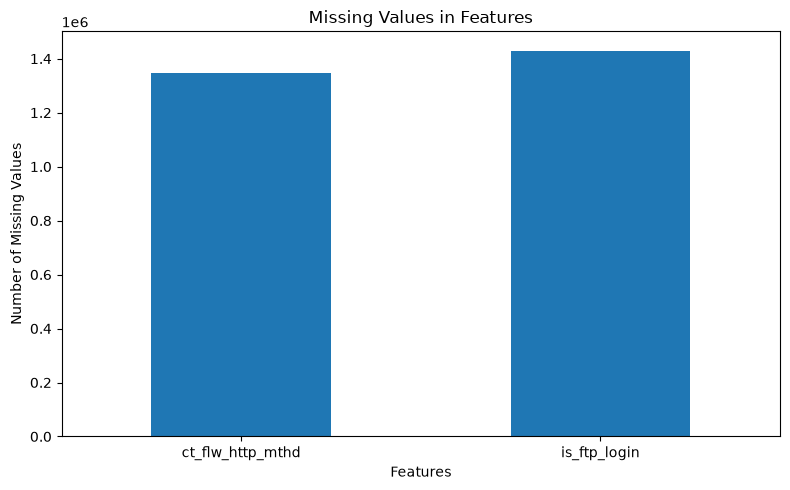

In [39]:
missing_data = df[feature_columns].isnull().sum()
missing_data = missing_data[missing_data > 0]

missing_data.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Missing Values in Features")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Inspecting Duplicate Records

In [40]:
print("Duplicate records:", df.duplicated().sum())

print(
    "Duplicate percentage:",
    (df.duplicated().sum() / len(df)) * 100
)

Duplicate records: 480632
Duplicate percentage: 18.922169550405957


#### Checking Duplicate Records Against Target Labels

In [41]:
duplicate_rows = df[df.duplicated(keep=False)]

pd.crosstab(
    duplicate_rows["Label"],
    duplicate_rows["attack_cat"].fillna("Normal")
)

attack_cat,Analysis,Backdoor,Backdoors,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Worms
Label,,,,,,,,,,
0,0,0,0,0,0,0,0,318950,0,0
1,908,209,470,12650,21344,3956,209179,0,1169,6


#### Checking Conflicting Duplicate Labels

In [42]:
feature_columns = df.columns.drop(["Label", "attack_cat"])

feature_hash = pd.util.hash_pandas_object(
    df[feature_columns],
    index=False
)

duplicate_check = pd.DataFrame({
    "feature_hash": feature_hash,
    "Label": df["Label"],
    "attack_cat": df["attack_cat"]
})

grouped = duplicate_check.groupby("feature_hash", sort=False).agg(
    label_count=("Label", "nunique"),
    attack_count=("attack_cat", "nunique")
)

print(
    "Identical feature groups with conflicting binary labels:",
    (grouped["label_count"] > 1).sum()
)

print(
    "Identical feature groups with multiple attack categories:",
    (grouped["attack_count"] > 1).sum()
)

Identical feature groups with conflicting binary labels: 0
Identical feature groups with multiple attack categories: 2251


#### Investigating Attack Category Inconsistency

In [43]:
print("Unique attack categories:")
print(df["attack_cat"].value_counts().sort_index())

print("\nBackdoor-related records:")
print(
    df["attack_cat"]
    .value_counts()
    .reindex(["Backdoor", "Backdoors"])
)

Unique attack categories:
attack_cat
Analysis            2677
Backdoor            1795
Backdoors            534
DoS                16353
Exploits           44525
Fuzzers            24246
Generic           215481
Reconnaissance     13987
Shellcode           1511
Worms                174
Name: count, dtype: int64

Backdoor-related records:
attack_cat
Backdoor     1795
Backdoors     534
Name: count, dtype: int64


#### Checking Categorical Value Consistency

In [44]:
for feature in categorical_features:
    print(f"\n{feature}:")
    print("Unique values:", df[feature].nunique())
    print("Missing values:", df[feature].isnull().sum())


srcip:
Unique values: 43
Missing values: 0

sport:
Unique values: 129124
Missing values: 0

dstip:
Unique values: 47
Missing values: 0

dsport:
Unique values: 64630
Missing values: 0

proto:
Unique values: 135
Missing values: 0

state:
Unique values: 16
Missing values: 0

service:
Unique values: 13
Missing values: 0

ct_ftp_cmd:
Unique values: 13
Missing values: 0


#### Examining Numerical Feature Distributions

In [45]:
df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
dur,2540047.0,6.587916e-01,1.392493e+01,0.000000e+00,1.037000e-03,1.586100e-02,2.145545e-01,8.786638e+03
sbytes,2540047.0,4.339600e+03,5.640599e+04,0.000000e+00,2.000000e+02,1.470000e+03,3.182000e+03,1.435577e+07
dbytes,2540047.0,3.642759e+04,1.610960e+05,0.000000e+00,1.780000e+02,1.820000e+03,1.489400e+04,1.465753e+07
sttl,2540047.0,6.278197e+01,7.462277e+01,0.000000e+00,3.100000e+01,3.100000e+01,3.100000e+01,2.550000e+02
dttl,2540047.0,3.076681e+01,4.285089e+01,0.000000e+00,2.900000e+01,2.900000e+01,2.900000e+01,2.540000e+02
sloss,2540047.0,5.163921e+00,2.251707e+01,0.000000e+00,0.000000e+00,3.000000e+00,7.000000e+00,5.319000e+03
dloss,2540047.0,1.632944e+01,5.659474e+01,0.000000e+00,0.000000e+00,4.000000e+00,1.400000e+01,5.507000e+03
Sload,2540047.0,3.695645e+07,1.186043e+08,0.000000e+00,1.353963e+05,5.893038e+05,2.039923e+06,5.988000e+09
Dload,2540047.0,2.450861e+06,4.224863e+06,0.000000e+00,1.191594e+04,5.893179e+05,2.925974e+06,1.287619e+08
Spkts,2540047.0,3.328884e+01,7.628388e+01,0.000000e+00,2.000000e+00,1.200000e+01,4.400000e+01,1.064600e+04


#### Checking Numerical Feature Skewness

In [46]:
df[numerical_features].skew().sort_values(ascending=False)

dur                 590.036391
trans_depth         148.640991
sbytes              142.981858
sloss               118.739427
Djit                 98.448415
Sjit                 47.651534
ackdat               42.821570
synack               40.538344
tcprtt               32.556720
Spkts                27.084605
Dintpkt              25.186158
is_sm_ips_ports      24.545800
res_bdy_len          18.926613
Sintpkt              18.733592
ct_flw_http_mthd     11.450605
dloss                 9.428584
dbytes                9.089084
Dpkts                 8.484065
Sload                 7.525025
is_ftp_login          5.463226
dttl                  4.548566
smeansz               3.698559
ct_src_dport_ltm      2.882653
ct_state_ttl          2.843124
ct_dst_ltm            2.714294
ct_dst_sport_ltm      2.620128
ct_src_ltm            2.598112
ct_dst_src_ltm        2.277547
sttl                  2.132909
ct_srv_dst            2.030828
ct_srv_src            1.979679
Dload                 1.955561
dmeansz 

#### Analyzing Numerical Feature Outliers

In [47]:
Q1 = df[numerical_features].quantile(0.25)
Q3 = df[numerical_features].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = (
    (df[numerical_features] < lower_bound) |
    (df[numerical_features] > upper_bound)
).sum()

outlier_counts.sort_values(ascending=False)

dttl                600080
sttl                599347
ct_dst_sport_ltm    570653
Sload               563157
ct_src_dport_ltm    533566
Sjit                473263
Dintpkt             453642
dur                 451297
Sintpkt             446036
ct_dst_src_ltm      415534
Djit                413969
ct_dst_ltm          362838
ct_state_ttl        361862
Dload               344566
ct_src_ltm          336932
ct_srv_src          313946
ct_srv_dst          310732
dbytes              301908
sbytes              287942
trans_depth         205122
ct_flw_http_mthd    205111
sloss               203863
res_bdy_len         186752
smeansz             169166
Dpkts               150493
Spkts               142681
dloss               129009
ackdat              125312
tcprtt              112171
synack              111218
is_ftp_login         43575
dmeansz              25587
is_sm_ips_ports       4195
Ltime                    0
Stime                    0
swin                     0
dwin                     0
s

#### Visualizing Numerical Feature Outliers

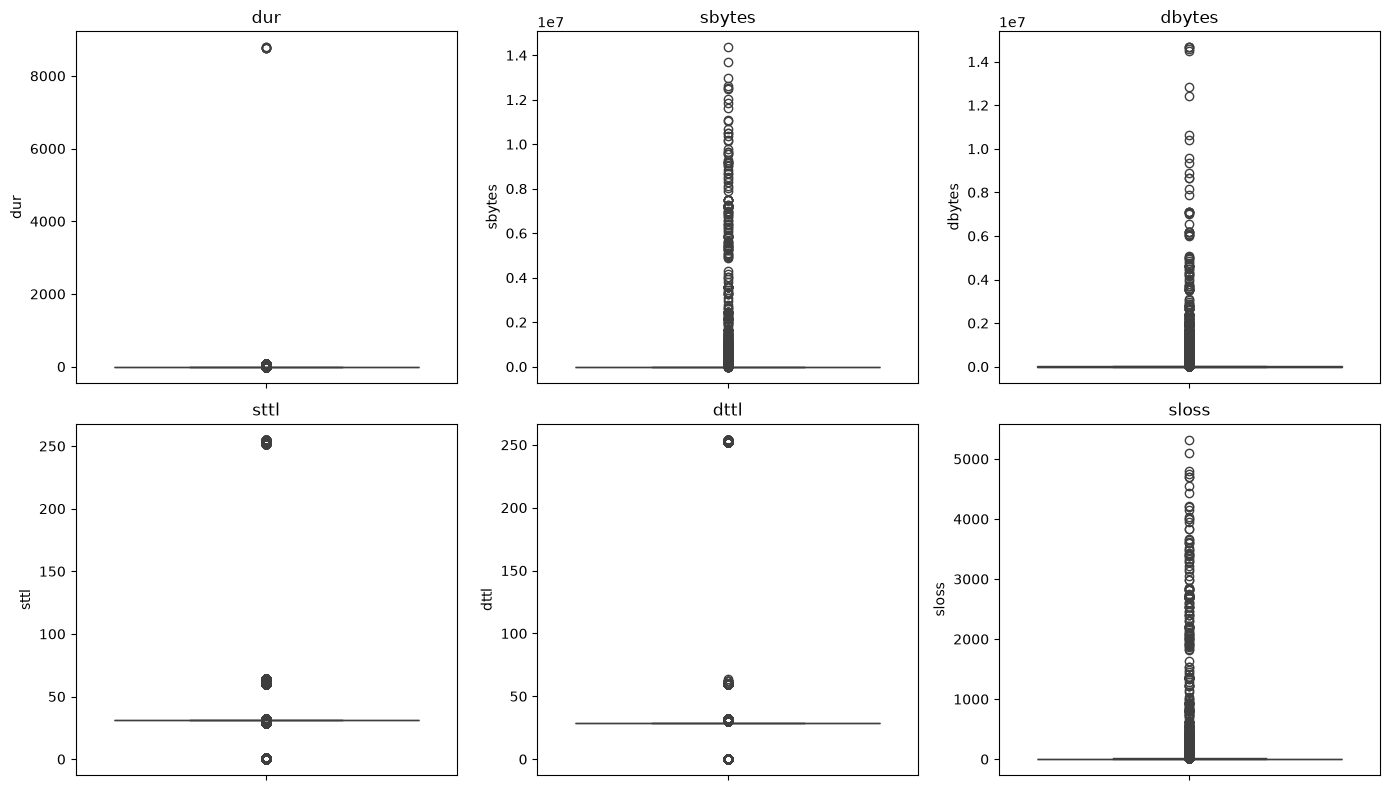

In [48]:
plt.figure(figsize=(14, 8))

for i, feature in enumerate(numerical_features[:6], 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[feature])
    plt.title(feature)

plt.tight_layout()
plt.show()

#### Examining Categorical Feature Distributions

In [49]:
for feature in categorical_features:
    print(f"\n{feature}:")
    print(df[feature].value_counts().head(10))


srcip:
srcip
59.166.0.4    197959
59.166.0.1    197680
59.166.0.5    197626
59.166.0.2    197550
59.166.0.0    197528
59.166.0.3    195953
59.166.0.9    190187
59.166.0.6    189419
59.166.0.8    189341
59.166.0.7    189059
Name: count, dtype: int64

sport:
sport
1043     214363
47439    196337
0         44376
0          9668
47439      6932
1043       5959
138        3480
5060        448
137         362
2048        357
Name: count, dtype: int64

dstip:
dstip
149.171.126.3    197771
149.171.126.2    197648
149.171.126.4    197639
149.171.126.1    197535
149.171.126.5    197000
149.171.126.0    196770
149.171.126.9    190483
149.171.126.7    190268
149.171.126.6    189709
149.171.126.8    187479
Name: count, dtype: int64

dsport:
dsport
53      798968
80      226698
6881    125156
5190    120599
111      93296
25       88748
0        54091
143      51065
22       50827
21       50518
Name: count, dtype: int64

proto:
proto
tcp     1495074
udp      990435
unas      16202
arp       10064


#### Examining Categorical Feature Cardinality

In [50]:
for feature in categorical_features:
    print(f"{feature}: {df[feature].nunique()} unique values")

srcip: 43 unique values
sport: 129124 unique values
dstip: 47 unique values
dsport: 64630 unique values
proto: 135 unique values
state: 16 unique values
service: 13 unique values
ct_ftp_cmd: 13 unique values


#### Checking Mixed Data Types

In [51]:
for feature in ["sport", "dsport", "ct_ftp_cmd"]:
    print(f"\n{feature}:")
    print(df[feature].apply(type).value_counts())


sport:
sport
<class 'int'>    1840046
<class 'str'>     700001
Name: count, dtype: int64

dsport:
dsport
<class 'str'>    2540047
Name: count, dtype: int64

ct_ftp_cmd:
ct_ftp_cmd
<class 'str'>    1840046
<class 'int'>     700001
Name: count, dtype: int64


#### Inspecting Mixed-Type Values

In [52]:
for feature in ["sport", "ct_ftp_cmd"]:
    print(f"\n{feature}:")
    print(df.loc[df[feature].apply(type) == str, feature].value_counts().head(15))


sport:
sport
0        9668
47439    6932
1043     5959
80        285
53        156
5190      125
25        115
143       108
6881       95
111        81
21         79
56724      76
5060       75
49320      68
59084      64
Name: count, dtype: int64

ct_ftp_cmd:
ct_ftp_cmd
     1429879
0     380306
1      29605
4        160
2         96
Name: count, dtype: int64


#### Checking Empty Strings in Categorical Features

In [56]:
for feature in categorical_features:
    empty_count = (df[feature] == "").sum()

    if empty_count > 0:
        print(f"{feature}: {empty_count} empty strings")

#### Verifying Blank Values in ct_ftp_cmd

In [57]:
print("Empty strings:", (df["ct_ftp_cmd"] == "").sum())
print("Whitespace-only strings:", df["ct_ftp_cmd"].apply(
    lambda x: isinstance(x, str) and x.strip() == ""
).sum())
print("Actual NaN values:", df["ct_ftp_cmd"].isna().sum())

Empty strings: 0
Whitespace-only strings: 1429879
Actual NaN values: 0


#### Checking Whitespace-Only Values Across Categorical Features

In [58]:
for feature in categorical_features:
    whitespace_count = df[feature].apply(
        lambda x: isinstance(x, str) and x.strip() == ""
    ).sum()

    if whitespace_count > 0:
        print(f"{feature}: {whitespace_count}")

ct_ftp_cmd: 1429879


#### Standardizing Whitespace-Only Values

In [59]:
df["ct_ftp_cmd"] = df["ct_ftp_cmd"].replace(
    r"^\s*$",
    np.nan,
    regex=True
)

print("Missing values in ct_ftp_cmd:", df["ct_ftp_cmd"].isna().sum())

Missing values in ct_ftp_cmd: 1429879


#### Standardizing Categorical Feature Data Types

In [60]:
df[categorical_features] = df[categorical_features].astype("string")

print(df[categorical_features].dtypes)

srcip         string
sport         string
dstip         string
dsport        string
proto         string
state         string
service       string
ct_ftp_cmd    string
dtype: object


#### Standardizing Attack Category Labels

In [61]:
df["attack_cat"] = df["attack_cat"].replace({
    "Backdoors": "Backdoor"
})

print(df["attack_cat"].value_counts())
print("\nUnique attack categories:", df["attack_cat"].nunique())

attack_cat
Generic           215481
Exploits           44525
Fuzzers            24246
DoS                16353
Reconnaissance     13987
Analysis            2677
Backdoor            2329
Shellcode           1511
Worms                174
Name: count, dtype: int64

Unique attack categories: 9


#### Verifying Categorical Feature Consistency

In [62]:
categorical_summary = pd.DataFrame({
    "Data Type": df[categorical_features].dtypes.astype(str),
    "Unique Values": df[categorical_features].nunique(),
    "Missing Values": df[categorical_features].isna().sum()
})

display(categorical_summary)

,Data Type,Unique Values,Missing Values
srcip,string,43,0
sport,string,64600,0
dstip,string,47,0
dsport,string,64630,0
proto,string,135,0
state,string,16,0
service,string,13,0
ct_ftp_cmd,string,8,1429879


#### Handling Missing Values in Categorical Features

In [63]:
df["ct_ftp_cmd"] = df["ct_ftp_cmd"].fillna("Unknown")

print("Remaining missing values:")
print(df[categorical_features].isna().sum())

print("\nct_ftp_cmd distribution:")
print(df["ct_ftp_cmd"].value_counts())

Remaining missing values:
srcip         0
sport         0
dstip         0
dsport        0
proto         0
state         0
service       0
ct_ftp_cmd    0
dtype: int64

ct_ftp_cmd distribution:
ct_ftp_cmd
Unknown    1429879
0          1066498
1            40077
2             1264
4              960
3              729
6              332
5              290
8               18
Name: count, dtype: Int64


#### Examining Numerical Features with Missing Values

In [64]:
missing_numerical_features = ["ct_flw_http_mthd", "is_ftp_login"]

for feature in missing_numerical_features:
    print(f"\n{feature}")
    print(df[feature].value_counts(dropna=False).sort_index())


ct_flw_http_mthd
ct_flw_http_mthd
0.0      986791
1.0      188008
2.0         588
3.0         738
4.0        6564
5.0         430
6.0        7902
8.0          56
9.0         270
10.0         30
12.0        132
14.0        224
16.0         48
25.0         25
30.0         60
36.0         36
NaN     1348145
Name: count, dtype: int64

is_ftp_login
is_ftp_login
0.0    1066593
1.0      43389
2.0         30
4.0        156
NaN    1429879
Name: count, dtype: int64


#### Analyzing Numerical Missing Values by Service

In [65]:
missing_by_service = df.groupby("service")[
    missing_numerical_features
].apply(lambda group: group.isna().sum())

display(missing_by_service)

,ct_flw_http_mthd,is_ftp_login
service,,
-,595228,596013
dhcp,165,165
dns,588156,588156
ftp,24229,1267
ftp-data,64115,64115
http,8044,111955
irc,28,28
pop3,1327,1327
radius,33,33


#### Creating Missingness Indicators

In [66]:
for feature in missing_numerical_features:
    df[f"{feature}_missing"] = df[feature].isna().astype("int8")

display(df[
    missing_numerical_features +
    [f"{feature}_missing" for feature in missing_numerical_features]
].head())

,ct_flw_http_mthd,is_ftp_login,ct_flw_http_mthd_missing,is_ftp_login_missing
0,0.0,0.0,0,0
1,0.0,0.0,0,0
2,0.0,0.0,0,0
3,0.0,0.0,0,0
4,0.0,0.0,0,0


#### Imputing Missing Numerical Values

In [67]:
df[missing_numerical_features] = df[missing_numerical_features].fillna(0)

print("Remaining missing values:")
print(df[missing_numerical_features].isna().sum())

Remaining missing values:
ct_flw_http_mthd    0
is_ftp_login        0
dtype: int64


#### Verifying Missing Values Across the Dataset

In [68]:
missing_summary = df.isna().sum()

print("Total missing values:", missing_summary.sum())
print("\nColumns with missing values:")
display(missing_summary[missing_summary > 0])

Total missing values: 2218764

Columns with missing values:


attack_cat    2218764
dtype: int64

#### Verifying Feature Completeness

In [69]:
all_feature_columns = numerical_features + categorical_features + [
    f"{feature}_missing" for feature in missing_numerical_features
]

print("Total feature columns:", len(all_feature_columns))
print("Total missing feature values:", df[all_feature_columns].isna().sum().sum())
print("Total target columns:", len(target_columns))

Total feature columns: 49
Total missing feature values: 0
Total target columns: 2


#### Rechecking Duplicate Records

In [70]:
duplicate_count = df.duplicated().sum()

print("Total records:", len(df))
print("Duplicate records:", duplicate_count)
print("Duplicate percentage:", round(
    duplicate_count / len(df) * 100, 2
), "%")

Total records: 2540047
Duplicate records: 480633
Duplicate percentage: 18.92 %


#### Examining Duplicate Records by Target Class

In [71]:
duplicate_rows = df[df.duplicated(keep=False)]

print("Duplicate records by binary target:")
display(duplicate_rows["Label"].value_counts())

print("\nDuplicate records by attack category:")
display(duplicate_rows["attack_cat"].value_counts())

Duplicate records by binary target:


Label
0    318952
1    249891
Name: count, dtype: int64


Duplicate records by attack category:


attack_cat
Generic           209179
Exploits           21344
DoS                12650
Fuzzers             3956
Reconnaissance      1169
Analysis             908
Backdoor             679
Worms                  6
Name: count, dtype: int64

#### Finalizing Feature and Target Columns

In [72]:
X = df[all_feature_columns].copy()

y_binary = df["Label"].copy()
y_multiclass = df["attack_cat"].copy()

print("Feature matrix:", X.shape)
print("Binary target:", y_binary.shape)
print("Multiclass target:", y_multiclass.shape)

print("\nBinary classes:")
print(y_binary.value_counts())

print("\nMulticlass classes:")
print(y_multiclass.value_counts())

Feature matrix: (2540047, 49)
Binary target: (2540047,)
Multiclass target: (2540047,)

Binary classes:
Label
0    2218764
1     321283
Name: count, dtype: int64

Multiclass classes:
attack_cat
Generic           215481
Exploits           44525
Fuzzers            24246
DoS                16353
Reconnaissance     13987
Analysis            2677
Backdoor            2329
Shellcode           1511
Worms                174
Name: count, dtype: int64


#### Preparing the Multiclass Dataset

In [73]:
attack_mask = y_binary == 1

X_multiclass = X.loc[attack_mask].copy()
y_multiclass = y_multiclass.loc[attack_mask].copy()

print("Multiclass feature matrix:", X_multiclass.shape)
print("Multiclass target:", y_multiclass.shape)

print("\nAttack category distribution:")
print(y_multiclass.value_counts())

Multiclass feature matrix: (321283, 49)
Multiclass target: (321283,)

Attack category distribution:
attack_cat
Generic           215481
Exploits           44525
Fuzzers            24246
DoS                16353
Reconnaissance     13987
Analysis            2677
Backdoor            2329
Shellcode           1511
Worms                174
Name: count, dtype: int64


#### Splitting the Binary Classification Dataset

In [74]:
from sklearn.model_selection import train_test_split

X_train_binary, X_test_binary, y_train_binary, y_test_binary = train_test_split(
    X,
    y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

print("Training features:", X_train_binary.shape)
print("Testing features:", X_test_binary.shape)

print("\nTraining target distribution:")
print(y_train_binary.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test_binary.value_counts(normalize=True) * 100)

Training features: (2032037, 49)
Testing features: (508010, 49)

Training target distribution:
Label
0    87.351313
1    12.648687
Name: proportion, dtype: float64

Testing target distribution:
Label
0    87.351233
1    12.648767
Name: proportion, dtype: float64


#### Splitting the Multiclass Classification Dataset

In [75]:
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multiclass,
    y_multiclass,
    test_size=0.2,
    random_state=42,
    stratify=y_multiclass
)

print("Training features:", X_train_multi.shape)
print("Testing features:", X_test_multi.shape)

print("\nTraining class distribution (%):")
print((y_train_multi.value_counts(normalize=True) * 100).round(3))

print("\nTesting class distribution (%):")
print((y_test_multi.value_counts(normalize=True) * 100).round(3))

Training features: (257026, 49)
Testing features: (64257, 49)

Training class distribution (%):
attack_cat
Generic           67.069
Exploits          13.859
Fuzzers            7.547
DoS                5.090
Reconnaissance     4.354
Analysis           0.833
Backdoor           0.725
Shellcode          0.470
Worms              0.054
Name: proportion, dtype: float64

Testing class distribution (%):
attack_cat
Generic           67.070
Exploits          13.858
Fuzzers            7.546
DoS                5.090
Reconnaissance     4.353
Analysis           0.833
Backdoor           0.725
Shellcode          0.470
Worms              0.054
Name: proportion, dtype: float64


#### Verifying Feature Consistency Across Splits

In [76]:
print("Binary feature columns match:",
      X_train_binary.columns.equals(X_test_binary.columns))

print("Multiclass feature columns match:",
      X_train_multi.columns.equals(X_test_multi.columns))

print("Binary training indices aligned:",
      X_train_binary.index.equals(y_train_binary.index))

print("Multiclass training indices aligned:",
      X_train_multi.index.equals(y_train_multi.index))

Binary feature columns match: True
Multiclass feature columns match: True
Binary training indices aligned: True
Multiclass training indices aligned: True


#### Identifying Numerical and Categorical Features for Modeling

In [77]:
numerical_features_final = numerical_features + [
    f"{feature}_missing" for feature in missing_numerical_features
]

categorical_features_final = categorical_features

print("Numerical features:", len(numerical_features_final))
print("Categorical features:", len(categorical_features_final))
print("Total features:",
      len(numerical_features_final) + len(categorical_features_final))

Numerical features: 41
Categorical features: 8
Total features: 49


#### Examining High-Cardinality Features

In [78]:
cardinality_summary = X_train_binary[categorical_features_final].nunique().sort_values(
    ascending=False
)

display(cardinality_summary)

dsport        64604
sport         64591
proto           135
dstip            47
srcip            43
state            16
service          13
ct_ftp_cmd        9
dtype: int64

#### Analyzing Port Feature Frequencies

In [79]:
for feature in ["sport", "dsport"]:
    print(f"\n{feature}")
    print("Unique values:", X_train_binary[feature].nunique())
    print("Values occurring once:", (X_train_binary[feature].value_counts() == 1).sum())
    print("Values occurring fewer than 10 times:",
          (X_train_binary[feature].value_counts() < 10).sum())
    print("Top 10 most frequent values:")
    display(X_train_binary[feature].value_counts().head(10))


sport
Unique values: 64591
Values occurring once: 51
Values occurring fewer than 10 times: 94
Top 10 most frequent values:


sport
1043     176163
47439    162555
0         43135
138        2773
5060        411
2048        327
137         311
80          304
53          217
68          177
Name: count, dtype: Int64


dsport
Unique values: 64604
Values occurring once: 184
Values occurring fewer than 10 times: 42209
Top 10 most frequent values:


dsport
53      638963
80      181304
6881    100159
5190     96585
111      74895
25       71100
0        43172
143      40866
22       40625
21       40371
Name: count, dtype: Int64

#### Preparing the Preprocessing Libraries

In [80]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

#### Building the Numerical Preprocessing Pipeline

In [81]:
numerical_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

print(numerical_transformer)

Pipeline(steps=[('scaler', StandardScaler())])


#### Building the Categorical Preprocessing Pipeline

In [82]:
categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=10,
        sparse_output=True
    ))
])

print(categorical_transformer)

Pipeline(steps=[('encoder',
                 OneHotEncoder(handle_unknown='infrequent_if_exist',
                               min_frequency=10))])


#### Combining Numerical and Categorical Pipelines

In [83]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features_final),
        ("cat", categorical_transformer, categorical_features_final)
    ],
    remainder="drop"
)

print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('scaler', StandardScaler())]),
                                 ['dur', 'sbytes', 'dbytes', 'sttl', 'dttl',
                                  'sloss', 'dloss', 'Sload', 'Dload', 'Spkts',
                                  'Dpkts', 'swin', 'dwin', 'stcpb', 'dtcpb',
                                  'smeansz', 'dmeansz', 'trans_depth',
                                  'res_bdy_len', 'Sjit', 'Djit', 'Stime',
                                  'Ltime', 'Sintpkt', 'Dintpkt', 'tcprtt',
                                  'synack', 'ackdat', 'is_sm_ips_ports',
                                  'ct_state_ttl', ...]),
                                ('cat',
                                 Pipeline(steps=[('encoder',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min_frequency=10))]),
       

#### Fitting and Transforming the Binary Dataset

In [84]:
X_train_binary_processed = preprocessor.fit_transform(X_train_binary)

X_test_binary_processed = preprocessor.transform(X_test_binary)

print("Training data shape:", X_train_binary_processed.shape)
print("Testing data shape:", X_test_binary_processed.shape)
print("Training data type:", type(X_train_binary_processed))
print("Testing data type:", type(X_test_binary_processed))

Training data shape: (2032037, 87189)
Testing data shape: (508010, 87189)
Training data type: <class 'scipy.sparse._csr.csr_matrix'>
Testing data type: <class 'scipy.sparse._csr.csr_matrix'>


#### Fitting and Transforming the Multiclass Dataset

In [85]:
from sklearn.base import clone

multiclass_preprocessor = clone(preprocessor)

X_train_multi_processed = multiclass_preprocessor.fit_transform(X_train_multi)

X_test_multi_processed = multiclass_preprocessor.transform(X_test_multi)

print("Training data shape:", X_train_multi_processed.shape)
print("Testing data shape:", X_test_multi_processed.shape)
print("Training data type:", type(X_train_multi_processed))
print("Testing data type:", type(X_test_multi_processed))

Training data shape: (257026, 410)
Testing data shape: (64257, 410)
Training data type: <class 'scipy.sparse._csr.csr_matrix'>
Testing data type: <class 'scipy.sparse._csr.csr_matrix'>


#### Validating the Preprocessed Datasets

In [86]:
from sklearn.utils import assert_all_finite

datasets = {
    "Binary Training": X_train_binary_processed,
    "Binary Testing": X_test_binary_processed,
    "Multiclass Training": X_train_multi_processed,
    "Multiclass Testing": X_test_multi_processed
}

for name, dataset in datasets.items():
    assert_all_finite(dataset)
    print(f"{name}: Valid")

print("\nBinary feature dimensions match:",
      X_train_binary_processed.shape[1] == X_test_binary_processed.shape[1])

print("Multiclass feature dimensions match:",
      X_train_multi_processed.shape[1] == X_test_multi_processed.shape[1])

Binary Training: Valid
Binary Testing: Valid
Multiclass Training: Valid
Multiclass Testing: Valid

Binary feature dimensions match: True
Multiclass feature dimensions match: True


#### Final Preprocessing Summary

In [87]:
print("BINARY CLASSIFICATION")
print("Training:", X_train_binary_processed.shape)
print("Testing:", X_test_binary_processed.shape)
print("Training class distribution:")
print(y_train_binary.value_counts())

print("\nMULTICLASS CLASSIFICATION")
print("Training:", X_train_multi_processed.shape)
print("Testing:", X_test_multi_processed.shape)
print("Training class distribution:")
print(y_train_multi.value_counts())

print("\nFEATURE CONFIGURATION")
print("Numerical features:", len(numerical_features_final))
print("Categorical features:", len(categorical_features_final))
print("Total original features:", len(all_feature_columns))

BINARY CLASSIFICATION
Training: (2032037, 87189)
Testing: (508010, 87189)
Training class distribution:
Label
0    1775011
1     257026
Name: count, dtype: int64

MULTICLASS CLASSIFICATION
Training: (257026, 410)
Testing: (64257, 410)
Training class distribution:
attack_cat
Generic           172384
Exploits           35620
Fuzzers            19397
DoS                13082
Reconnaissance     11190
Analysis            2142
Backdoor            1863
Shellcode           1209
Worms                139
Name: count, dtype: int64

FEATURE CONFIGURATION
Numerical features: 41
Categorical features: 8
Total original features: 49


#### Checking Duplicate Leakage Across Splits

In [88]:
train_hashes = pd.util.hash_pandas_object(
    X_train_binary, index=False
)

test_hashes = pd.util.hash_pandas_object(
    X_test_binary, index=False
)

train_unique_hashes = set(train_hashes.unique())
test_unique_hashes = set(test_hashes.unique())

overlapping_hashes = train_unique_hashes.intersection(test_unique_hashes)

print("Unique training feature combinations:", len(train_unique_hashes))
print("Unique testing feature combinations:", len(test_unique_hashes))
print("Feature combinations present in both sets:", len(overlapping_hashes))

Unique training feature combinations: 1654389
Unique testing feature combinations: 443768
Feature combinations present in both sets: 49541


#### Quantifying Cross-Split Duplicate Overlap

In [89]:
train_hash_counts = train_hashes.value_counts()
test_hash_counts = test_hashes.value_counts()

overlap_summary = pd.DataFrame({
    "Training Records": train_hash_counts,
    "Testing Records": test_hash_counts
}).dropna()

print("Overlapping unique feature combinations:", len(overlap_summary))
print("Training records in overlapping groups:",
      overlap_summary["Training Records"].sum())
print("Testing records in overlapping groups:",
      overlap_summary["Testing Records"].sum())

Overlapping unique feature combinations: 49541
Training records in overlapping groups: 363712.0
Testing records in overlapping groups: 112149.0


#### Checking Target Consistency Across Overlapping Groups

In [90]:
train_label_data = pd.DataFrame({
    "feature_hash": train_hashes.to_numpy(),
    "Label": y_train_binary.to_numpy()
})

test_label_data = pd.DataFrame({
    "feature_hash": test_hashes.to_numpy(),
    "Label": y_test_binary.to_numpy()
})

overlap_labels = pd.concat(
    [train_label_data, test_label_data],
    ignore_index=True
)

overlap_label_summary = overlap_labels[
    overlap_labels["feature_hash"].isin(overlapping_hashes)
].groupby("feature_hash").agg(
    unique_labels=("Label", "nunique"),
    total_records=("Label", "size")
)

print("Overlapping groups with conflicting binary labels:",
      (overlap_label_summary["unique_labels"] > 1).sum())

print("Total records in conflicting groups:",
      overlap_label_summary.loc[
          overlap_label_summary["unique_labels"] > 1,
          "total_records"
      ].sum())

Overlapping groups with conflicting binary labels: 0
Total records in conflicting groups: 0


#### Checking Multiclass Cross-Split Overlap

In [91]:
train_multi_hashes = pd.util.hash_pandas_object(
    X_train_multi, index=False
)

test_multi_hashes = pd.util.hash_pandas_object(
    X_test_multi, index=False
)

multi_train_hashes = set(train_multi_hashes.unique())
multi_test_hashes = set(test_multi_hashes.unique())

multi_overlapping_hashes = multi_train_hashes.intersection(
    multi_test_hashes
)

print("Unique training feature combinations:", len(multi_train_hashes))
print("Unique testing feature combinations:", len(multi_test_hashes))
print("Overlapping feature combinations:", len(multi_overlapping_hashes))

Unique training feature combinations: 75830
Unique testing feature combinations: 31616
Overlapping feature combinations: 18601


#### Checking Multiclass Target Consistency Across Splits

In [92]:
train_multi_label_data = pd.DataFrame({
    "feature_hash": train_multi_hashes.to_numpy(),
    "attack_cat": y_train_multi.to_numpy()
})

test_multi_label_data = pd.DataFrame({
    "feature_hash": test_multi_hashes.to_numpy(),
    "attack_cat": y_test_multi.to_numpy()
})

multi_overlap_labels = pd.concat(
    [train_multi_label_data, test_multi_label_data],
    ignore_index=True
)

multi_overlap_summary = multi_overlap_labels[
    multi_overlap_labels["feature_hash"].isin(multi_overlapping_hashes)
].groupby("feature_hash").agg(
    unique_categories=("attack_cat", "nunique"),
    total_records=("attack_cat", "size")
)

conflicting_groups = multi_overlap_summary[
    multi_overlap_summary["unique_categories"] > 1
]

print("Overlapping groups with conflicting attack categories:",
      len(conflicting_groups))

print("Total records in conflicting groups:",
      conflicting_groups["total_records"].sum())

Overlapping groups with conflicting attack categories: 2004
Total records in conflicting groups: 39186


#### Examining Conflicting Attack Categories

In [93]:
conflicting_hashes = conflicting_groups.index

conflicting_records = multi_overlap_labels[
    multi_overlap_labels["feature_hash"].isin(conflicting_hashes)
]

conflict_distribution = (
    conflicting_records
    .groupby(["feature_hash", "attack_cat"])
    .size()
    .reset_index(name="record_count")
)

display(
    conflict_distribution
    .sort_values("record_count", ascending=False)
    .head(20)
)

,feature_hash,attack_cat,record_count
8420,12252062884396011654,DoS,40
8421,12252062884396011654,Exploits,35
9181,13479721615862496045,Exploits,30
12184,18180762829716154165,Exploits,30
9233,13537562432609384165,Exploits,27
10755,15778126170230799935,Exploits,24
1069,1522676430502578655,Exploits,24
7408,10769665675777602769,Exploits,24
7096,10202670808969230761,DoS,24
9420,13743710581793828553,DoS,24


#### Analyzing Conflicting Attack Category Pairs

In [94]:
conflict_pairs = (
    conflicting_records
    .groupby(["feature_hash", "attack_cat"])
    .size()
    .unstack(fill_value=0)
)

category_pair_counts = {}

for i, category_a in enumerate(conflict_pairs.columns):
    for category_b in conflict_pairs.columns[i + 1:]:
        count = (
            (conflict_pairs[category_a] > 0) &
            (conflict_pairs[category_b] > 0)
        ).sum()

        if count > 0:
            category_pair_counts[
                f"{category_a} - {category_b}"
            ] = count

display(
    pd.Series(category_pair_counts, name="Conflicting Groups")
    .sort_values(ascending=False)
)

DoS - Exploits               1901
Exploits - Fuzzers           1862
DoS - Fuzzers                1851
Analysis - Exploits          1698
Analysis - DoS               1697
Analysis - Fuzzers           1697
Exploits - Generic           1664
Exploits - Reconnaissance    1638
DoS - Generic                1635
Fuzzers - Reconnaissance     1617
DoS - Reconnaissance         1617
Generic - Reconnaissance     1612
Fuzzers - Generic            1612
Backdoor - Exploits          1596
Backdoor - DoS               1592
Backdoor - Fuzzers           1591
Analysis - Generic           1474
Analysis - Reconnaissance    1469
Analysis - Backdoor          1447
Backdoor - Generic           1363
Backdoor - Reconnaissance    1359
Exploits - Worms                2
DoS - Worms                     1
Name: Conflicting Groups, dtype: int64

#### Measuring Multiclass Label Ambiguity

In [95]:
ambiguous_records = conflicting_groups["total_records"].sum()
total_attack_records = len(X_multiclass)

print("Records in conflicting groups:", ambiguous_records)
print("Total attack records:", total_attack_records)

print(
    "Ambiguous record percentage:",
    round(ambiguous_records / total_attack_records * 100, 2),
    "%"
)

Records in conflicting groups: 39186
Total attack records: 321283
Ambiguous record percentage: 12.2 %


#### Final Preprocessing Validation

In [96]:
print("BINARY CLASSIFICATION")
print("Training:", X_train_binary_processed.shape)
print("Testing:", X_test_binary_processed.shape)
print("Missing values:", X_train_binary.isna().sum().sum())

print("\nMULTICLASS CLASSIFICATION")
print("Training:", X_train_multi_processed.shape)
print("Testing:", X_test_multi_processed.shape)
print("Missing values:", X_train_multi.isna().sum().sum())

print("\nPREPROCESSING")
print("Numerical features:", len(numerical_features_final))
print("Categorical features:", len(categorical_features_final))

print("\nDATA QUALITY")
print("Duplicate records retained:", duplicate_count)
print("Multiclass ambiguous records:", ambiguous_records)
print("Multiclass ambiguity (%):",
      round(ambiguous_records / total_attack_records * 100, 2))

print("\nAll preprocessing validation checks completed.")

BINARY CLASSIFICATION
Training: (2032037, 87189)
Testing: (508010, 87189)
Missing values: 0

MULTICLASS CLASSIFICATION
Training: (257026, 410)
Testing: (64257, 410)
Missing values: 0

PREPROCESSING
Numerical features: 41
Categorical features: 8

DATA QUALITY
Duplicate records retained: 480633
Multiclass ambiguous records: 39186
Multiclass ambiguity (%): 12.2

All preprocessing validation checks completed.


#### Saving Preprocessing Artifacts

In [97]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(preprocessor, MODEL_DIR / "binary_preprocessor.pkl")

joblib.dump(
    multiclass_preprocessor,
    MODEL_DIR / "multiclass_preprocessor.pkl"
)

print("Preprocessing artifacts saved successfully.")

Preprocessing artifacts saved successfully.
